# Dataset and CCTV video exploration

Inspect the supplied CCTV clip, metadata, frame sampling, scene coverage and annotation needs.

## Inspect metadata

In [1]:
from pathlib import Path
import cv2

video_path = Path('../data/raw/video.mp4')

cap = cv2.VideoCapture(str(video_path))

fps = cap.get(cv2.CAP_PROP_FPS)
frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

print({'fps': fps, 'frames': frames, 'duration_s': frames / fps if fps else None,
       'width': width, 'height': height})
cap.release()

{'fps': 30.0, 'frames': 950, 'duration_s': 31.666666666666668, 'width': 2568, 'height': 1440}


## Sample frames

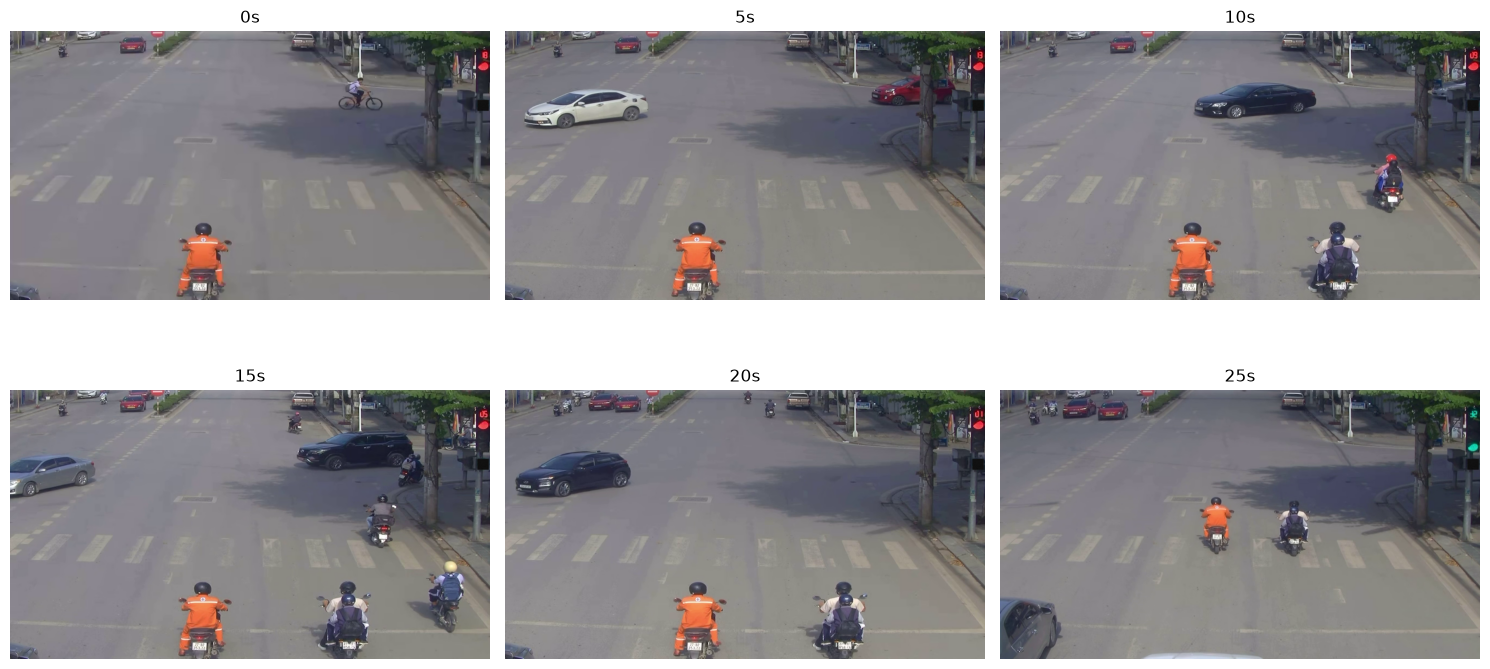

In [2]:
import matplotlib.pyplot as plt

cap = cv2.VideoCapture(str(video_path))
seconds = [0, 5, 10, 15, 20, 25]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, sec in zip(axes.flat, seconds):
    cap.set(cv2.CAP_PROP_POS_MSEC, sec * 1000)
    ok, frame = cap.read()
    
    if ok:
        ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    
    ax.set_title(f'{sec}s')
    ax.axis('off')

cap.release()
plt.tight_layout()